# Modelagem com MLflow

Com o dataset tratado na seção 1 e as variáveis de interesse selecionadas e com  o racional de construção documentado. A partir da regra dura encontrada incialmente (amount > 200), serão testadas algumas abordagens focadas na redução de falsos positivos, o principal entrave a aplicar essa heurística simples.

Para isso, será monitorado na construção dos modelos:

* `pr_auc`, `roc_auc`, `ks`
* `recall_at_0.05`, `recall_at_0.1`: recall bloqueando score ≥ 0,05 e ≥ 0,1
* `total_cost`: custo operacional (R$) da decisão de bloqueio, via `utils.pnl.decision_pnl`

Será utilizado uma instancia local do MLFlow, adicionado como dependência desse projeto, para acompanhamento dos experimentos e decisão do modelo mais adequado para a estratégia analítica.

Servidor de tracking local (rodar na raiz do projeto antes do notebook):

```bash
mlflow server --backend-store-uri sqlite:///mlflow.db --artifacts-destination ./mlartifacts --host 127.0.0.1 --port 5000

In [87]:
import sys

import lightgbm as lgb
import mlflow
import mlflow.lightgbm
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

sys.path.append("../")

from utils.metrics import *
from utils.pnl import decision_pnl, optimal_threshold, threshold_cost_curve
from utils.woe import WoEEncoder
import matplotlib.pyplot as plt
from utils.plots import plot_model_results

import warnings

warnings.filterwarnings("ignore")

In [88]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("nuvemshop-fraude")

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1791777698885, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791777698885, lifecycle_stage='active', name='nuvemshop-fraude', tags={}, trace_location=None, workspace='default'>

In [89]:
df = pd.read_csv('../data/nuvem_fraud_dataset_pos_eda.csv', sep=';')

In [90]:
df.head()

,created_at,txn_id,customer_id,amount,vertical,is_fraud,txns_prev_1h,amount_to_customer_median_ratio_30d,n_high_prev_24h
0,2019-01-01 00:00:44+00:00,0,122,107.23,grocery_pos,0,0,NaN,0
1,2019-01-01 00:00:51+00:00,1,63,220.11,entertainment,0,0,NaN,0
2,2019-01-01 00:07:27+00:00,2,23,96.29,grocery_pos,0,0,NaN,0
3,2019-01-01 00:09:03+00:00,3,83,7.77,shopping_pos,0,0,NaN,0
4,2019-01-01 00:21:32+00:00,4,81,6.85,misc_pos,0,0,NaN,0


---

# Criação das bases de treino, validação e teste

In [91]:
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df['safra'] = df["ym"] = df["created_at"].dt.strftime("%Y-%m")


In [92]:
AMOUNT = 200
NIGHT_HOURS = [22, 23, 0, 1, 2, 3]
RISK_VERTICALS = ['shopping_net', 'grocery_pos', 'misc_net', 'shopping_pos']

def data_prep(df):
    df['high_amount'] = df['amount'] > AMOUNT
    df["night"] = np.where(df["created_at"].dt.hour.isin(NIGHT_HOURS), 1, 0)
    df['risk_vertical'] = np.where(df['vertical'].isin(RISK_VERTICALS), 1, 0)
    df['amount_to_customer_median_ratio_30d_gt_5'] = np.where(df['amount_to_customer_median_ratio_30d'] > 5, 1, 0)
    df = df.fillna(0)
    return df[['txn_id', 'customer_id', 'created_at', 'amount', 'high_amount', 'night', 'risk_vertical', 
               'txns_prev_1h','amount_to_customer_median_ratio_30d_gt_5',	'n_high_prev_24h', 'is_fraud' ]]

In [93]:
df = data_prep(df)

Como foram encontrados perfis associados a clientes únicos, faz-se necessário o cálculo de variáveis históricas d-1 e d-30 para algumas abordagens. Também é necessário observar a maturação relativa a contestação ou disputa do chargeback. Para isso, considera-se uma janela de um mês entre a data de envento e o período de observação.

Desse modo, descarta-se o primeiro mês do histórico para construção dos modelos supervisionados. 2020-05 e 2025-09 também são removidos como periodos de maturação de fraude entre os blocos de validação e teste

In [94]:
df["ym"] = df["created_at"].dt.strftime("%Y-%m")
conds = [
    df.ym < "2019-02",
    df.ym.between("2019-02", "2020-04"),
    df.ym == "2020-05",
    df.ym.between("2020-06", "2020-08"),
    df.ym == "2020-09",
    df.ym >= "2020-10",
]
df["split"] = np.select(
    conds,
    ["warmup", "train", "gap1", "valid", "gap2", "test"],
    default="unassigned",
)
df.groupby("split")["is_fraud"].agg(["size", "sum", "mean"])

,size,sum,mean
split,,,
gap1,13494,81,0.006003
gap2,12793,69,0.005394
test,51557,171,0.003317
train,203934,1159,0.005683
valid,48135,203,0.004217
warmup,9694,99,0.010213


In [95]:
target = "is_fraud"

train = df[df["split"] == "train"].copy()
valid = df[df["split"] == "valid"].copy()
test = df[df["split"] == "test"].copy()

splits = {"train": train, "valid": valid, "test": test}

---

Para avaliação de cada estratégia analítica dessa seção, serão medidos tanto os indicadores relacionados à performance do modelo, como métricas de ordenação PR-AUC (principal métrica), ROC-AUC e KS, descritas no módulo utils.metrics desse projeto, utilizando as méticas padrão da biblioteca scikit-learn.

Para estimativa de custos de  cada estratégia, definiu-se a função abaixo (persistida no modulo utils.pnl desse projeto), aplicando o racional de custos e margem definidas no problema, a partir do 

```python
import numpy as np
import pandas as pd

CHARGEBACK_FEE = 15.0
MARGIN = 0.10


def decision_pnl(
    y_true,
    blocked,
    amount,
    chargeback_fee: float = CHARGEBACK_FEE,
    margin: float = MARGIN
 ) -> dict[str, float]:
    """Matriz de confusão e custo total (R$) de uma decisão de bloqueio."""
    y = np.asarray(y_true).astype(bool)
    b = np.asarray(blocked).astype(bool)
    a = np.asarray(amount, dtype=float)

    fn = y & ~b
    fp = ~y & b
    fn_cost = (a[fn] + chargeback_fee).sum()
    fp_cost = (margin * a[fp] ).sum()
    approve_all_cost = (a[y] + chargeback_fee).sum()
    total_cost = fn_cost + fp_cost

    return {
        "n_txns": len(y),
        "block_rate": b.mean(),
        "tp": int((y & b).sum()),
        "fp": int(fp.sum()),
        "fn": int(fn.sum()),
        "tn": int((~y & ~b).sum()),
        "recall": (y & b).sum() / max(y.sum(), 1),
        "precision": (y & b).sum() / max(b.sum(), 1),
        "fraud_amount_blocked_pct": a[y & b].sum() / max(a[y].sum(), 1e-9),
        "fn_cost": fn_cost,
        "fp_cost": fp_cost,
        "total_cost": total_cost,
        "savings_vs_approve_all": approve_all_cost - total_cost,
    }


def threshold_cost_curve(
    y_true,
    y_score,
    amount,
    chargeback_fee: float = CHARGEBACK_FEE,
    margin: float = MARGIN,
) -> pd.DataFrame:
    """Custo total para cada threshold candidato (bloqueia se score >= threshold).

    Os candidatos são os scores únicos observados, mais um threshold acima do
    máximo (aprovar tudo).
    """
    y = np.asarray(y_true).astype(bool)
    s = np.asarray(y_score, dtype=float)
    a = np.asarray(amount, dtype=float)

    order = np.argsort(-s, kind="stable")
    s, y, a = s[order], y[order], a[order]

    # Custo de bloquear cada transação em relação a aprová-la:
    # fraude bloqueada economiza amount + fee; legítima bloqueada custa margem + análise.
    approve_all_cost = (a[y] + chargeback_fee).sum()
    delta = np.where(y, -(a + chargeback_fee), margin * a )

    # Bloquear o top-k: considera apenas o último índice de cada score (empates)
    last_of_tie = np.r_[s[1:] != s[:-1], True]
    k = np.flatnonzero(last_of_tie) + 1

    cum_delta = np.cumsum(delta)[k - 1]
    cum_fraud = np.cumsum(y)[k - 1]
    n_fraud = y.sum()

    curve = pd.DataFrame(
        {
            "threshold": s[k - 1],
            "n_blocked": k,
            "block_rate": k / len(s),
            "recall": cum_fraud / max(n_fraud, 1),
            "precision": cum_fraud / k,
            "total_cost": approve_all_cost + cum_delta,
        }
    )
    approve_all = pd.DataFrame(
        {
            "threshold": [np.inf],
            "n_blocked": [0],
            "block_rate": [0.0],
            "recall": [0.0],
            "precision": [np.nan],
            "total_cost": [approve_all_cost],
        }
    )
    curve = pd.concat([approve_all, curve], ignore_index=True)
    curve["savings_vs_approve_all"] = approve_all_cost - curve["total_cost"]
    return curve


def optimal_threshold(curve: pd.DataFrame) -> float:
    """Threshold de menor custo total na curva."""
    return float(curve.loc[curve["total_cost"].idxmin(), "threshold"])



Para a avaliação do modelo nesse case, serão usadas as funções abaixo nas chamadas dos experimentos

In [ ]:
pnl_params = {"chargeback_fee": 15.0, "margin": 0.10}


def evaluate(y_true, y_score, amount, threshold: float) -> dict[str, float]:
    y = np.asarray(y_true).astype(bool)
    s = np.asarray(y_score, dtype=float)
    pnl = decision_pnl(y, s >= threshold, amount, **pnl_params)
    return {
        **{k: v for k, v in classification_metrics(y, s).items() if k in ("pr_auc", "roc_auc", "ks")},
        "recall_at_0.05": (y & (s >= 0.05)).sum() / max(y.sum(), 1),
        "recall_at_0.1": (y & (s >= 0.1)).sum() / max(y.sum(), 1),
        **{k: pnl[k] for k in ("block_rate", "recall", "precision", "fn_cost", "fp_cost",
                               "total_cost", "savings_vs_approve_all")},
    }


def evaluate_splits(scores: dict[str, np.ndarray], threshold: float) -> pd.DataFrame:
    return pd.DataFrame(
        {name: evaluate(data[target], scores[name], data["amount"], threshold)
         for name, data in splits.items()}
    ).T


def log_split_metrics(metrics: pd.DataFrame) -> None:
    mlflow.log_metrics(
        {f"{split}_{metric}": float(value)
         for split, row in metrics.iterrows() for metric, value in row.items()}
    )

---

# 1 - Regra de Valor > 200

SImulação da regra fria para comparativo. Bloqueia toda transação acima de R$ 200. O score é a própria flag (0 ou 1), então o threshold de decisão é 1 e `recall_at_0.05` = `recall_at_0.1` = recall da regra.

In [ ]:
train

,txn_id,customer_id,created_at,amount,high_amount,night,risk_vertical,txns_prev_1h,amount_to_customer_median_ratio_30d,n_high_prev_24h,is_fraud,ym,split
9694,9694,81,2019-02-01 00:03:27+00:00,13.01,False,1,1,0,0.935298,0,0,2019-02,train
9695,9695,99,2019-02-01 00:08:20+00:00,32.14,False,1,0,1,0.930785,0,0,2019-02,train
9696,9696,83,2019-02-01 00:12:33+00:00,108.99,False,1,1,1,3.204646,0,0,2019-02,train
9697,9697,85,2019-02-01 00:27:38+00:00,1.01,False,1,0,0,0.020476,0,0,2019-02,train
9698,9698,52,2019-02-01 00:33:56+00:00,78.53,False,1,1,0,2.233504,0,0,2019-02,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...
213623,213623,162,2020-04-30 23:49:07+00:00,1.33,False,1,1,0,0.028608,0,0,2020-04,train
213624,213624,8,2020-04-30 23:51:58+00:00,137.19,False,1,0,0,3.176062,0,0,2020-04,train
213625,213625,73,2020-04-30 23:53:37+00:00,75.29,False,1,0,0,1.615665,0,0,2020-04,train
213626,213626,17,2020-04-30 23:54:55+00:00,891.32,True,1,1,1,15.066261,3,1,2020-04,train


In [ ]:

rule_scores = {name: data["high_amount"].to_numpy() for name, data in splits.items()}
rule_metrics = evaluate_splits(rule_scores, threshold=1.0)

with mlflow.start_run(run_name="regra_amount_gt_200"):
    mlflow.set_tag("model_type", "rule")
    mlflow.log_params({"rule": f"amount > {200}", "decision_threshold": 1.0, **pnl_params})
    log_split_metrics(rule_metrics)

rule_metrics

🏃 View run regra_amount_gt_200 at: http://127.0.0.1:5000/#/experiments/1/runs/9e8470e544cf4e2ca7a10105ef09029e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.066542,0.855015,0.710029,0.755824,0.755824,0.049830,0.755824,0.086204,11632.21,399456.200,411088.410,200227.130
valid,0.048390,0.840090,0.680180,0.724138,0.724138,0.046827,0.724138,0.065217,2574.55,88675.141,91249.691,17303.879
test,0.034347,0.824941,0.649882,0.695906,0.695906,0.048180,0.695906,0.047907,2038.59,102117.594,104156.184,-16509.484


Para esse baseline, nota-se que perde cerca de 5% do recall no dataset de teste, com uma piora significativa da precisão, causando uma perda significativa da performance nos dados de teste. Para essa partição, nota-se que há uma **perda** de receita no uso da regra ao invés da aprovação geral.

O objetivo das próximas iterações é reduzir o volume de falsos positivos, mantendo a precisão dessa abordagem inicial.

# 2 - Regressão Logística Univariada ( variável binária  "Valor > 200")

A seguir, serão testados algumas abordagens utilizando regressão logística nas principais variáveis encontradas na análise exploratória de dados. A principal razão do uso da regressão logística se deve ao fato da facilidade de interpretação dos parâmetros e por consequencia, explicabilidade e rastreabilidade do modelo. Ap final dos experimentps, serão testados metodologias desafiantes ("challengers") usando ensembles de árvores de decisão, que embora não sejam tão transparentes com relação ao uso de modelos lineares, apresentam sistematicamente melhores resultados para modelos supervisionados por serem mais flexíveis para capturar padrões complexos, como não-linearidade. 

As funções abaixo são usadas para o treino, extração dos coeficientes e registro dos logs das execuções dos experimentos a seguir.

In [ ]:
import mlflow


def fit_logreg(features: list[str], target: str = "is_fraud") -> LogisticRegression:
    return LogisticRegression(max_iter=1000).fit(train[features], train[target])


def logreg_coefs(model: LogisticRegression, features: list[str]) -> pd.Series:
    return pd.Series(np.append(model.intercept_, model.coef_.ravel()),
                     index=["intercept", *features], name="coef")


def log_experiment(run_name: str, model, features: list[str], step: int, params: dict) -> pd.DataFrame:
    """Calcula scores, escolhe o threshold de menor custo na validação e registra no MLflow."""
    scores = {name: model.predict_proba(data[features])[:, 1] for name, data in splits.items()}
    curve_valid = threshold_cost_curve(valid[target], scores["valid"], valid["amount"], **pnl_params)
    threshold = optimal_threshold(curve_valid)
    metrics = evaluate_splits(scores, threshold=threshold)

    model_type = "logistic_regression" if isinstance(model, LogisticRegression) else "lightgbm"
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({"model_type": model_type, "step": step})
        mlflow.log_params({"features": ",".join(features), "decision_threshold": threshold,
                           **params, **pnl_params})
        log_split_metrics(metrics)
    return metrics


results = {(0, "regra"): rule_metrics}

In [ ]:
logreg_features_1 = ["high_amount"]
logreg_1 = fit_logreg(logreg_features_1)
results[(1, "logreg")] = log_experiment("logreg_amount_gt_200", logreg_1, logreg_features_1, step=1,
                                        params={"C": logreg_1.C})

display(logreg_coefs(logreg_1, logreg_features_1))
results[(1, "logreg")]


🏃 View run logreg_amount_gt_200 at: http://127.0.0.1:5000/#/experiments/1/runs/24e13926fb9f448f913546e228143027
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept     -6.489853
high_amount    4.112729
Name: coef, dtype: float64

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.066542,0.855015,0.710029,0.755824,0.0,0.049830,0.755824,0.086204,11632.21,399456.200,411088.410,200227.130
valid,0.048390,0.840090,0.680180,0.724138,0.0,0.046827,0.724138,0.065217,2574.55,88675.141,91249.691,17303.879
test,0.034347,0.824941,0.649882,0.695906,0.0,0.048180,0.695906,0.047907,2038.59,102117.594,104156.184,-16509.484


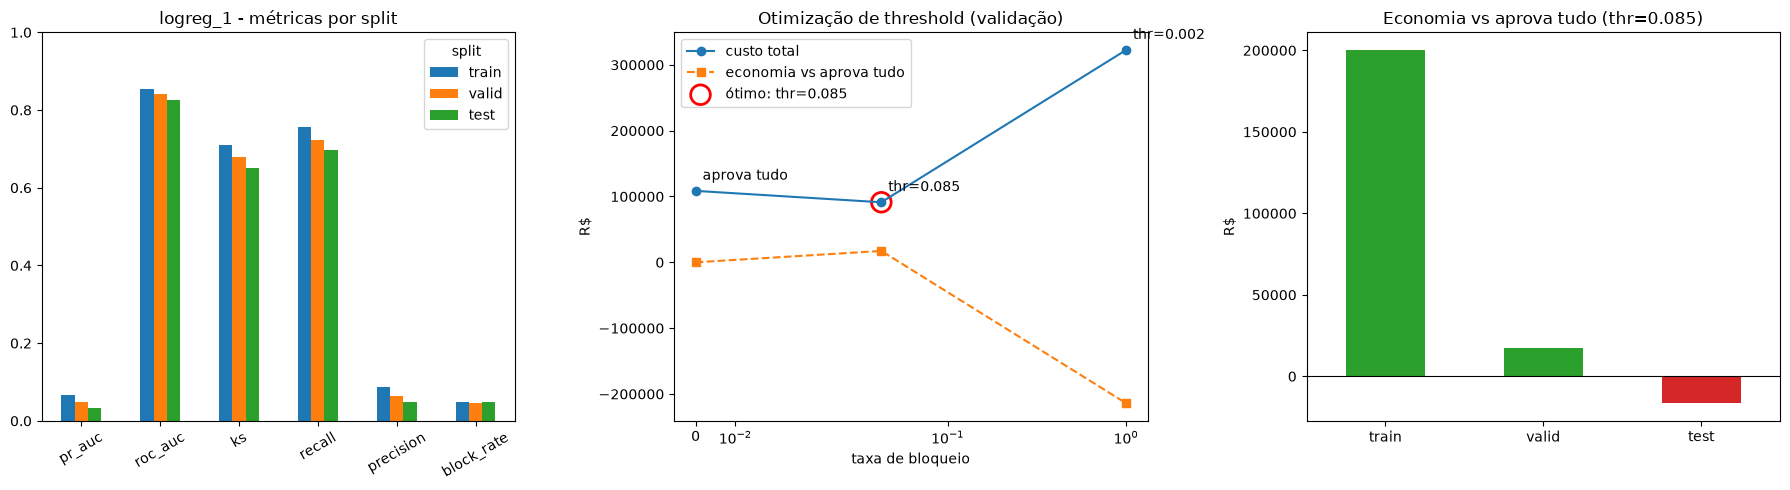

In [ ]:

lr1_curve = threshold_cost_curve(
    valid[target], logreg_1.predict_proba(valid[logreg_features_1])[:, 1], valid["amount"], **pnl_params
)
plot_model_results(results[(1, "logreg")], lr1_curve, model_name="logreg_1")
plt.show()


**Run 1 — `high_amount`.** Com uma única variável binária, a regressão logística só gera dois scores, e a curva de custo tem três pontos (aprovar tudo, bloquear > R$ 200, bloquear tudo). O ótimo reproduz exatamente a regra fria: mesmas métricas, inclusive o prejuízo de R$ 16,5 mil no teste. Serve como baseline "modelado" para as próximas iterações. (`recall_at_0.1` = 0 porque o score de `high_amount = 1` fica abaixo de 0,1.)

# 3 - Regressão Logística (Valor + Hora Transação)

In [ ]:
logreg_features_2 = ["high_amount", 'night']
logreg_2 = fit_logreg(logreg_features_2)
results[(2, "logreg_night")] = log_experiment("logreg_amount_gt_200_night", logreg_2, logreg_features_2, step=2,
                                        params={"C": logreg_2.C})

display(logreg_coefs(logreg_2, logreg_features_2))
results[2,
  'logreg_night']

🏃 View run logreg_amount_gt_200_night at: http://127.0.0.1:5000/#/experiments/1/runs/a6252907472d4999bd10daa377682b01
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept     -8.127161
high_amount    4.005825
night          3.014902
Name: coef, dtype: float64

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.177978,0.941827,0.710029,0.648835,0.648835,0.014573,0.648835,0.253028,101413.91,93090.954,194504.864,416810.676
valid,0.139755,0.933036,0.696404,0.645320,0.645320,0.013421,0.645320,0.202786,12734.66,19945.373,32680.033,75873.537
test,0.086059,0.917517,0.676740,0.549708,0.549708,0.013189,0.549708,0.138235,21939.95,24245.930,46185.880,41460.820


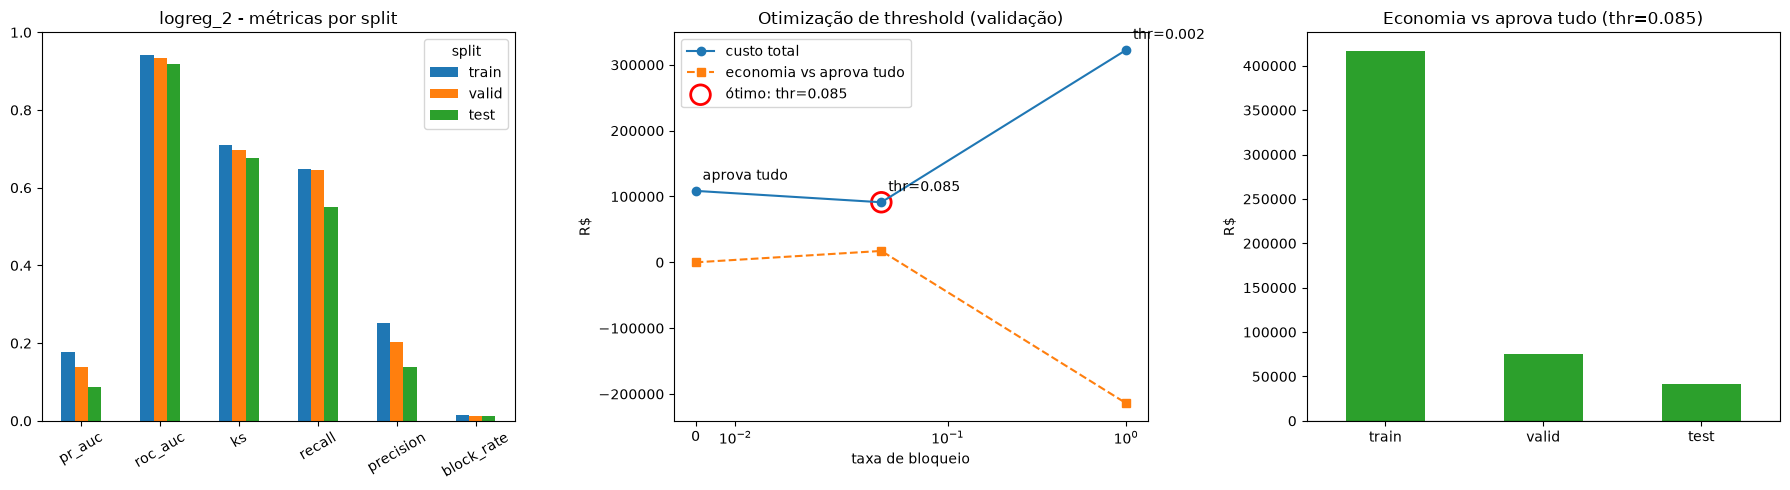

In [ ]:
lr2_curve = threshold_cost_curve(
    valid[target], logreg_2.predict_proba(valid[logreg_features_2])[:, 1], valid["amount"], **pnl_params
)
plot_model_results(results[(2,
  'logreg_night')], lr2_curve, model_name="logreg_2")
plt.show()

**Run 2 — `high_amount` + `night`.** O horário noturno tem peso comparável ao valor (coef. 3,0 vs 4,0). O modelo passa a bloquear apenas transações altas *e* noturnas: a taxa de bloqueio cai de ~4,8% para ~1,3% e a precisão no teste quase triplica (4,8% → 13,8%). O recall cai (70% → 55%), mas a redução de falsos positivos transforma o prejuízo da regra no teste em economia de R$ 41,5 mil.

In [ ]:
logreg_features_3 = ["high_amount", 'night', 'risk_vertical']
logreg_3 = fit_logreg(logreg_features_3)
results[(3, "logreg_night_vertical")] = log_experiment("logreg_amount_gt_200_night_vertical", logreg_3, logreg_features_3, step=3,
                                        params={"C": logreg_3.C})

display(logreg_coefs(logreg_3, logreg_features_3))
results[3,
  'logreg_night_vertical']

🏃 View run logreg_amount_gt_200_night_vertical at: http://127.0.0.1:5000/#/experiments/1/runs/fe95d355718e4d209b3e43fee5ddc215
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept       -8.272953
high_amount      3.932854
night            2.965425
risk_vertical    0.374561
Name: coef, dtype: float64

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.213631,0.931916,0.718489,0.648835,0.648835,0.014573,0.648835,0.253028,101413.91,93090.954,194504.864,416810.676
valid,0.168854,0.920682,0.696404,0.645320,0.645320,0.013421,0.645320,0.202786,12734.66,19945.373,32680.033,75873.537
test,0.112715,0.903995,0.676740,0.549708,0.549708,0.013189,0.549708,0.138235,21939.95,24245.930,46185.880,41460.820


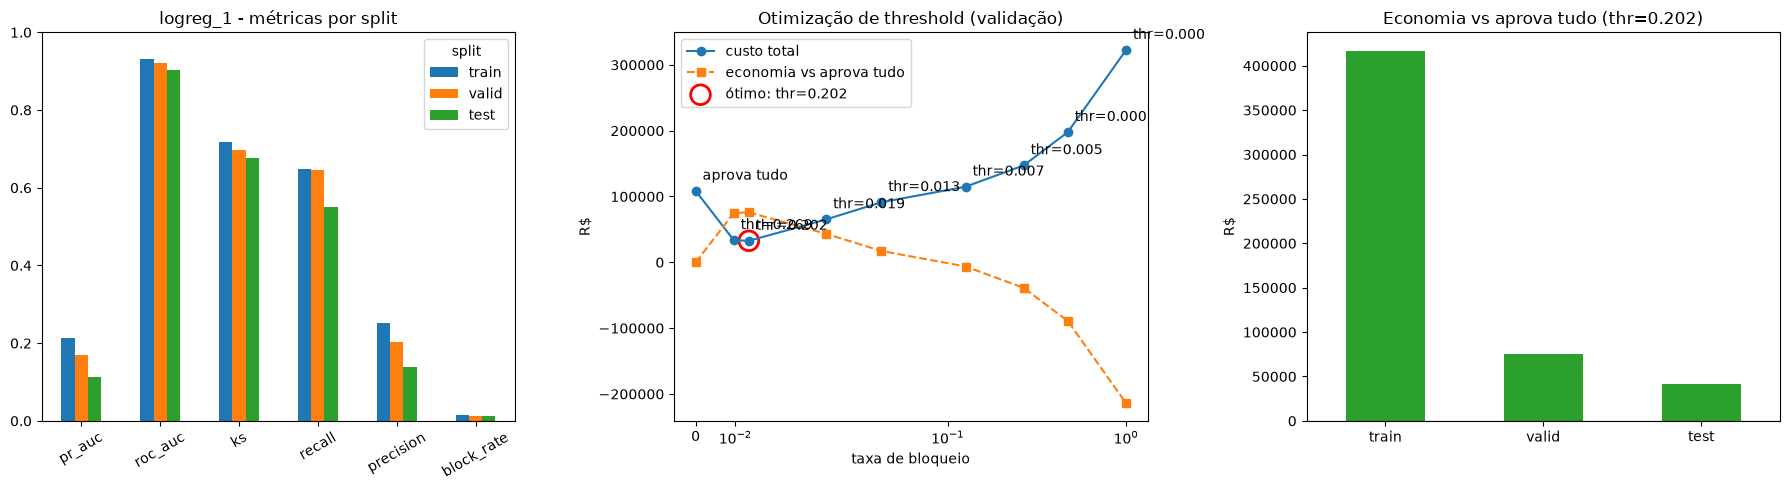

In [ ]:
lr3_curve = threshold_cost_curve(
    valid[target], logreg_3.predict_proba(valid[logreg_features_3])[:, 1], valid["amount"], **pnl_params
)
plot_model_results(results[(3,
  'logreg_night_vertical')], lr3_curve, model_name="logreg_3")
plt.show()

**Run 3 — + `risk_vertical`.** A vertical de risco melhora a ordenação (PR-AUC teste 0,086 → 0,113), mas seu coeficiente é pequeno (0,37) e não muda a decisão: o threshold ótimo seleciona exatamente as mesmas transações do run 2, então as métricas de decisão e custo são idênticas.

In [ ]:
logreg_features_4 = ["high_amount", 'night', 'risk_vertical','txns_prev_1h']
logreg_4 = fit_logreg(logreg_features_4)
results[(4, "logreg_night_vertical_1h")] = log_experiment("logreg_amount_gt_200_night_vertical_1h", logreg_4, logreg_features_4, step=4,
                                        params={"C": logreg_4.C})

display(logreg_coefs(logreg_4, logreg_features_4))
results[4,
  'logreg_night_vertical_1h']

🏃 View run logreg_amount_gt_200_night_vertical_1h at: http://127.0.0.1:5000/#/experiments/1/runs/6ff7c1576e444084b18f93b1f631bda8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept       -8.576194
high_amount      3.920045
night            2.900297
risk_vertical    0.292060
txns_prev_1h     1.055446
Name: coef, dtype: float64

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.377730,0.942545,0.775889,0.661777,0.654012,0.011764,0.628991,0.303877,115004.81,70876.643,185881.453,425434.087
valid,0.293068,0.933368,0.758321,0.660099,0.650246,0.010699,0.635468,0.250485,14224.95,14897.183,29122.133,79431.437
test,0.199422,0.914150,0.748393,0.567251,0.555556,0.010726,0.538012,0.166365,22742.98,18007.161,40750.141,46896.559


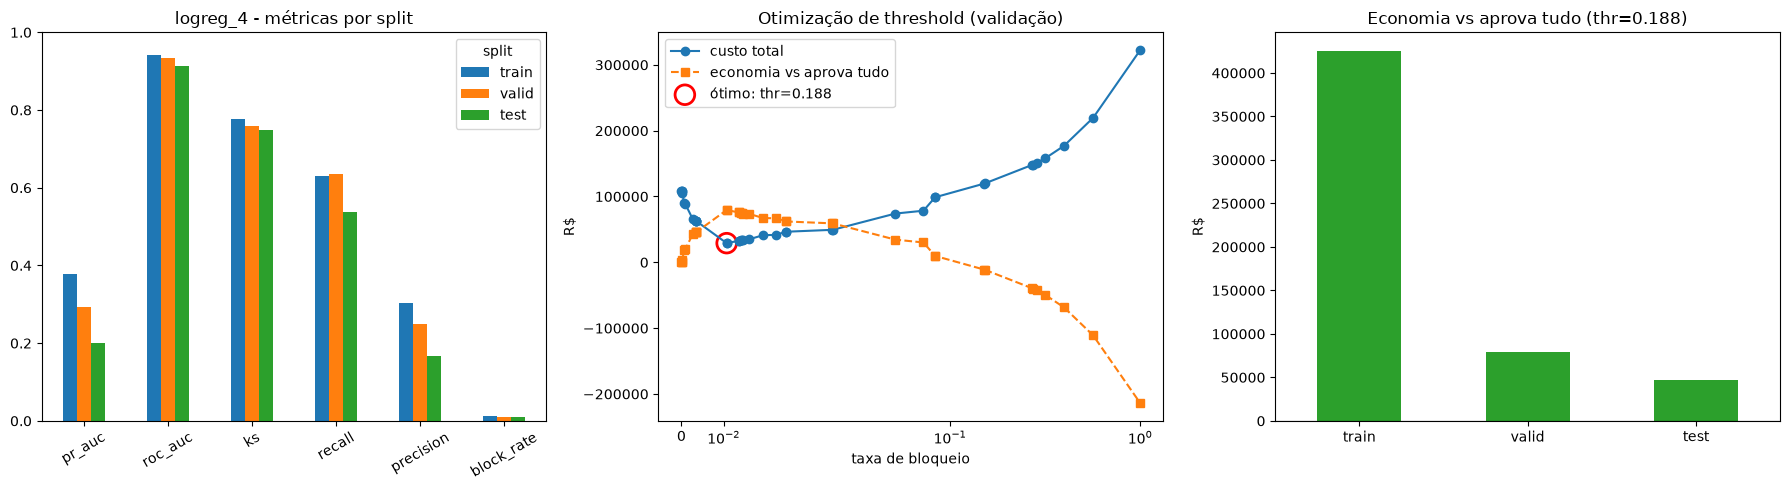

In [ ]:
lr4_curve = threshold_cost_curve(
    valid[target], logreg_4.predict_proba(valid[logreg_features_4])[:, 1], valid["amount"], **pnl_params
)
plot_model_results(results[(4,
  'logreg_night_vertical_1h')], lr4_curve, model_name="logreg_4")
plt.show()

**Run 4 — + `txns_prev_1h`.** Velocidade do cliente (transações na última hora). Primeiro ganho expressivo de ordenação: PR-AUC de teste 0,11 → 0,20 e KS 0,68 → 0,75. Com mais níveis de score, a curva de custo permite um corte mais fino: bloqueio cai para ~1,1% com custo de FP menor, e a economia no teste sobe para R$ 46,9 mil.

In [97]:
logreg_features_5 = ["high_amount", 'night', 'risk_vertical','txns_prev_1h', 'amount_to_customer_median_ratio_30d_gt_5']
logreg_5 = fit_logreg(logreg_features_5)
results[(5, "logreg_night_vertical_1h_customer_median")] = log_experiment("logreg_amount_gt_200_night_vertical_1h_customer_median", logreg_5, logreg_features_5, step=5,
                                        params={"C": logreg_5.C})

display(logreg_coefs(logreg_5, logreg_features_5))
results[5,
  'logreg_night_vertical_1h_customer_median']

🏃 View run logreg_amount_gt_200_night_vertical_1h_customer_median at: http://127.0.0.1:5000/#/experiments/1/runs/a09399ec346a4c0e8ee82b96830bfd3a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept                                  -8.766080
high_amount                                 3.128429
night                                       3.023462
risk_vertical                               0.448700
txns_prev_1h                                1.052205
amount_to_customer_median_ratio_30d_gt_5    1.007371
Name: coef, dtype: float64

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.405687,0.942730,0.767908,0.661777,0.650561,0.008468,0.572045,0.383903,145685.63,57571.047,203256.677,408058.863
valid,0.348575,0.934420,0.759534,0.660099,0.645320,0.007728,0.630542,0.344086,14552.76,11778.074,26330.834,82222.736
test,0.219201,0.915348,0.736133,0.567251,0.549708,0.007177,0.491228,0.227027,27151.96,14169.212,41321.172,46325.528


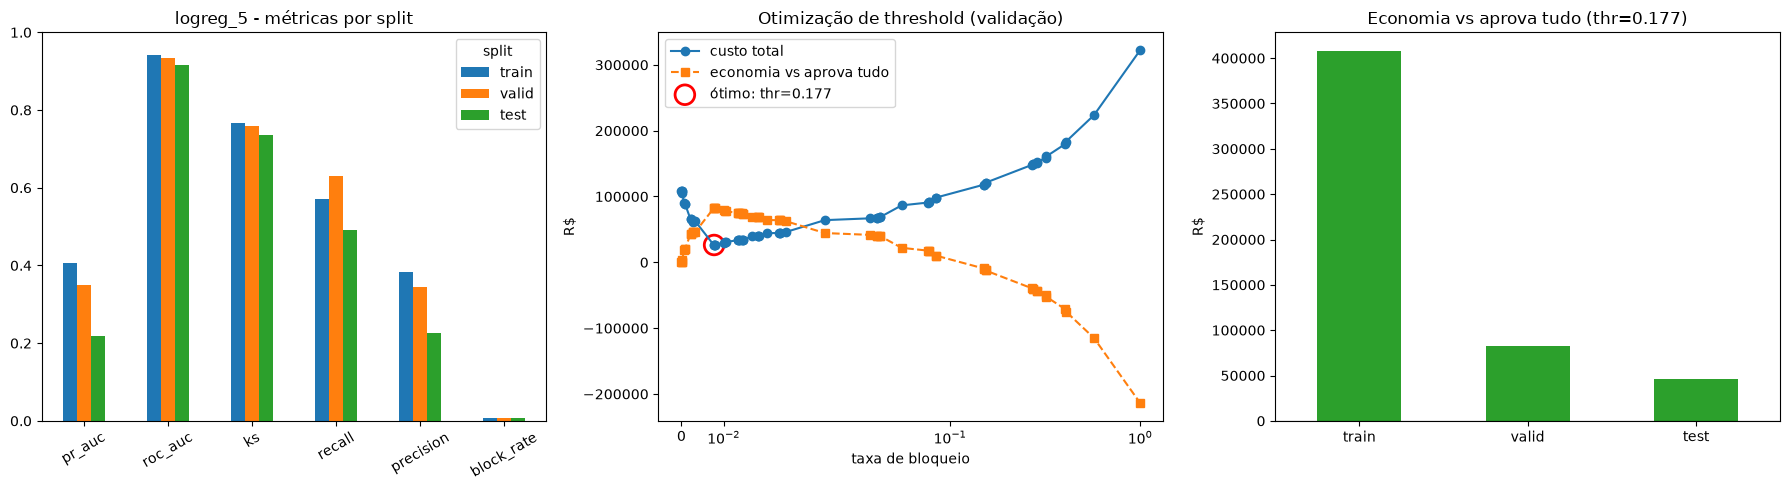

In [98]:
lr5_curve = threshold_cost_curve(
    valid[target], logreg_5.predict_proba(valid[logreg_features_5])[:, 1], valid["amount"], **pnl_params
)
plot_model_results(results[(5,
  'logreg_night_vertical_1h_customer_median')], lr5_curve, model_name="logreg_5")
plt.show()

**Run 5 — + `amount_to_customer_median_ratio_30d_gt_5`.** Flag de valor 5x acima da mediana do cliente em 30 dias. Melhora a ordenação (PR-AUC teste 0,20 → 0,22) e a precisão (0,17 → 0,23), mas o threshold ótimo fica mais conservador: bloqueia menos e o recall de teste cai para 49%. Economia de teste praticamente igual à do run 4 — ganho de qualidade sem ganho financeiro.

In [100]:
logreg_features_6 = ["high_amount", 'night', 'risk_vertical','txns_prev_1h', 'amount_to_customer_median_ratio_30d_gt_5', 'n_high_prev_24h']
logreg_6 = fit_logreg(logreg_features_6)
results[(6, "logreg_night_vertical_1h_customer_median_high24h")] = log_experiment("logreg_amount_gt_200_night_vertical_1h_customer_median_high24h", logreg_6, logreg_features_6, step=6,
                                        params={"C": logreg_6.C})

display(logreg_coefs(logreg_6, logreg_features_6))
results[6,
  'logreg_night_vertical_1h_customer_median_high24h']

🏃 View run logreg_amount_gt_200_night_vertical_1h_customer_median_high24h at: http://127.0.0.1:5000/#/experiments/1/runs/273ba77f9b1d4e9d96c8d6486dce1121
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept                                  -9.593144
high_amount                                 2.480428
night                                       2.988251
risk_vertical                               0.112786
txns_prev_1h                                0.254171
amount_to_customer_median_ratio_30d_gt_5    1.635841
n_high_prev_24h                             1.519880
Name: coef, dtype: float64

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.708736,0.980520,0.877025,0.812770,0.722174,0.012141,0.796376,0.372779,55831.80,68986.954,124818.754,486496.786
valid,0.629961,0.975415,0.882345,0.798030,0.704433,0.011489,0.798030,0.292948,5354.32,15303.870,20658.190,87895.380
test,0.531430,0.944639,0.806707,0.754386,0.666667,0.012549,0.736842,0.194745,11179.03,19275.480,30454.510,57192.190


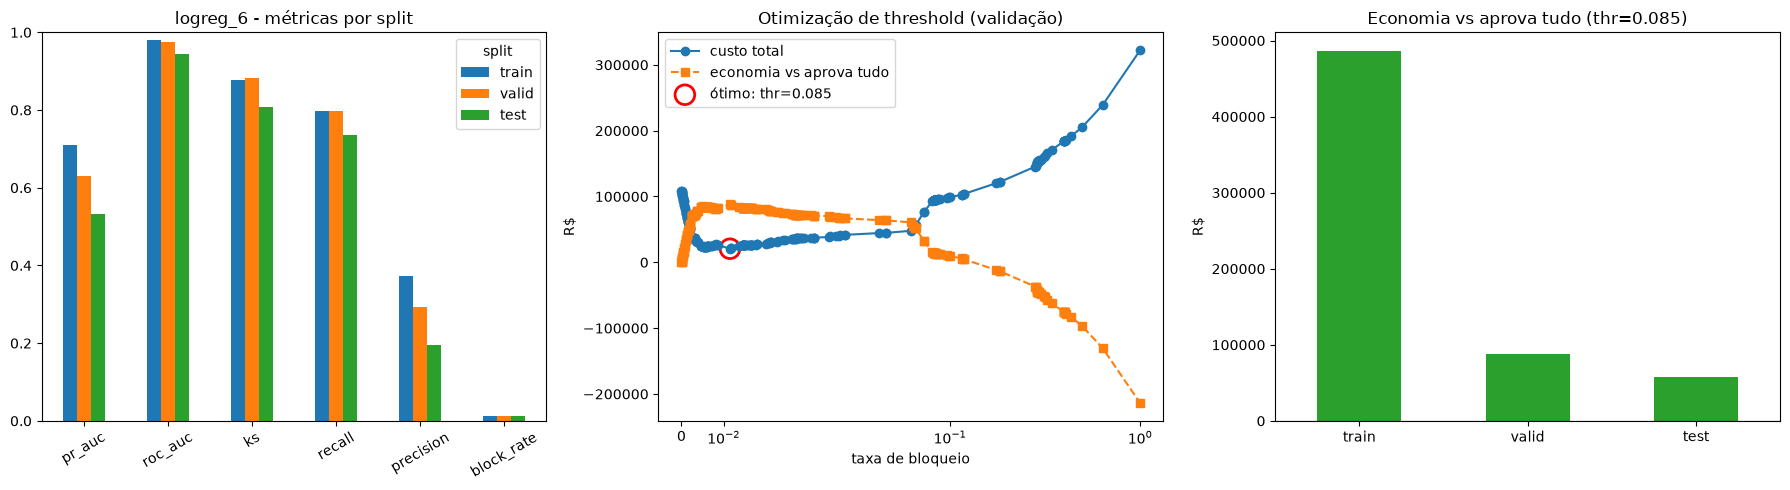

In [102]:
lr6_curve = threshold_cost_curve(
    valid[target], logreg_6.predict_proba(valid[logreg_features_6])[:, 1], valid["amount"], **pnl_params
)
plot_model_results(results[(6,
  'logreg_night_vertical_1h_customer_median_high24h')], lr6_curve, model_name="logreg_6")
plt.show()

**Run 6 — + `n_high_prev_24h`.** Maior salto da série: PR-AUC de teste vai de 0,22 para 0,53 e KS para 0,81. O histórico de transações de alto valor do cliente nas últimas 24h captura o padrão de "rajada" da fraude. O ótimo da validação passa a recuperar ~74% das fraudes no teste bloqueando ~1,3% das transações, com a maior economia vs aprova-tudo no teste (R$ 57,2 mil). Note que `high_amount`, `risk_vertical` e `txns_prev_1h` perdem peso — parte da informação deles agora é explicada por `n_high_prev_24h`, o que motiva a checagem de multicolinearidade abaixo.

# Checagem de multicolinearidade

Antes de seguir com o conjunto final do run 6, verifica-se se as variáveis selecionadas são redundantes entre si. Multicolinearidade não prejudica a ordenação do modelo, mas torna os coeficientes instáveis e difíceis de interpretar — justamente a vantagem que motivou o uso da regressão logística.

Dois diagnósticos na base de treino:
* **Correlação de Spearman** entre pares (|ρ| > 0,7 indica redundância);
* **VIF** (Variance Inflation Factor): < 5 aceitável, 5–10 atenção, > 10 problemático.

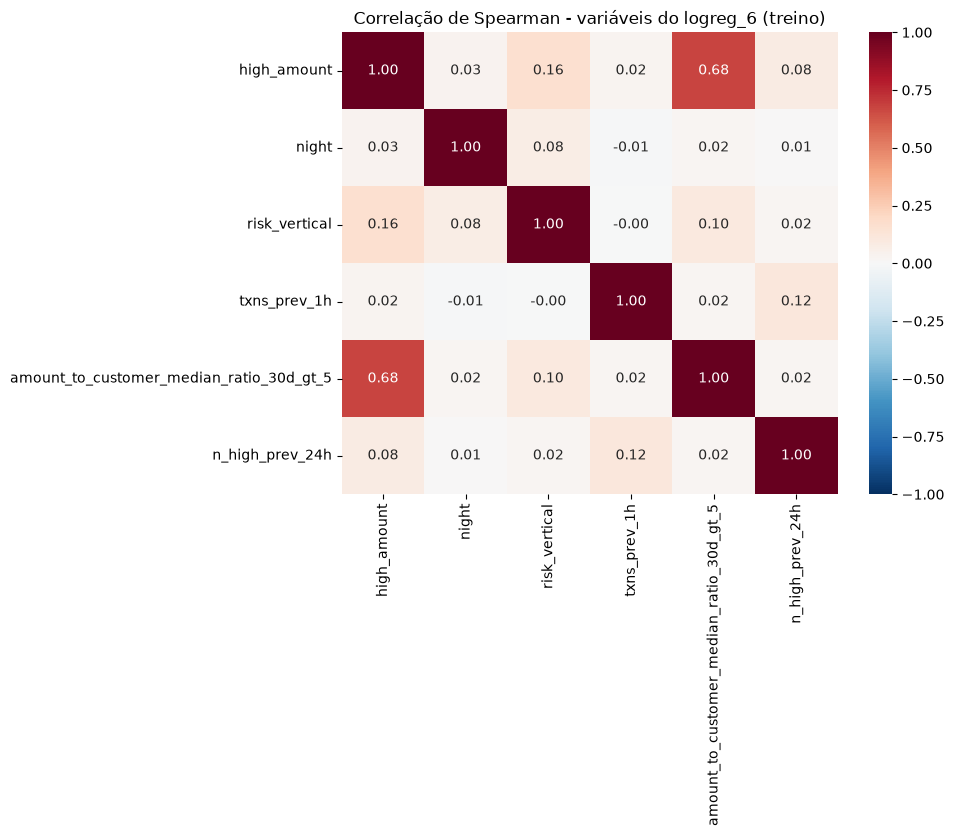

,VIF,status
high_amount,1.912813,ok
amount_to_customer_median_ratio_30d_gt_5,1.859522,ok
n_high_prev_24h,1.042332,ok
risk_vertical,1.031478,ok
txns_prev_1h,1.022961,ok
night,1.007149,ok


In [103]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns

X_vif = train[logreg_features_6].astype(float)

corr = X_vif.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação de Spearman - variáveis do logreg_6 (treino)")
plt.show()

X_const = add_constant(X_vif)
vif = pd.Series(
    [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])],
    index=logreg_features_6, name="VIF",
).sort_values(ascending=False)
vif.to_frame().assign(status=lambda d: pd.cut(d["VIF"], [0, 5, 10, np.inf], labels=["ok", "atenção", "alto"]))

**Leitura:** _preencher após execução._ Se algum VIF passar de 5 (candidatos esperados: `high_amount` × `n_high_prev_24h` e `txns_prev_1h` × `n_high_prev_24h`, que medem facetas parecidas de valor e velocidade), avaliar remover a variável de menor contribuição ou comparar a estabilidade dos coeficientes entre treino e validação.

---

# Teste Modelo Challenger  -LIGHTGBM

Usando o mesmo conjunto de variáveis da regressão logística 6, testou-se o uso de um ensemble de árvores com LIGHTGBM com as configurações padrão (usando apenas uma configuração de early stopping para evitar overfitting). Houve um pequeno ganho (cerca de 4 mil unidades, 7% de economia), bloqueando um volume ligeiramente menor de transações boas. 

É um bom modelo desafiante para a regressão logística, mas para fins produtivos em uma etapa inicial, seguiria com a rgressão logística, rodando o LightGBM em paralelo (fora do motor de decisão), uma vez que a regressão logística é facilmente mais explicável e auditável do que o lightgbm (que demandaria estratégias menos diretas de explicabilidade como SHAP, LIME e outras técnicas)

In [106]:
lgbm = lgb.LGBMClassifier(

).fit(
    train[logreg_features_6],
    train[target],
    eval_set=[(valid[logreg_features_6], valid[target])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

results[(7, "lgbm")] = log_experiment(
    "lgbm_night_vertical_1h_customer_median_high24h", lgbm, logreg_features_6, step=7, params=lgbm.get_params()
)

print(f"Melhor iteração: {lgbm.best_iteration_}")
pd.Series(
    lgbm.booster_.feature_importance(importance_type="gain"),
    index=logreg_features_6,
    name="gain",
).sort_values(ascending=False).pipe(lambda s: s / s.sum())

[LightGBM] [Info] Number of positive: 1159, number of negative: 202775
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010922 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27
[LightGBM] [Info] Number of data points in the train set: 203934, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.005683 -> initscore=-5.164539
[LightGBM] [Info] Start training from score -5.164539
🏃 View run lgbm_night_vertical_1h_customer_median_high24h at: http://127.0.0.1:5000/#/experiments/1/runs/62ec1b5d4fd94b9f827f80c9bd99a140
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Melhor iteração: 36


n_high_prev_24h                             0.485032
night                                       0.208933
amount_to_customer_median_ratio_30d_gt_5    0.117184
txns_prev_1h                                0.091383
high_amount                                 0.066030
risk_vertical                               0.031438
Name: gain, dtype: float64

In [113]:
display(results[7,
  'lgbm'])

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.718618,0.978401,0.888207,0.792062,0.714409,0.009861,0.772217,0.445052,73332.56,50673.634,124006.194,487309.346
valid,0.623180,0.974999,0.888059,0.783251,0.689655,0.008829,0.778325,0.371765,7537.81,10919.079,18456.889,90096.681
test,0.506451,0.962490,0.834536,0.742690,0.678363,0.008980,0.725146,0.267819,12947.44,13730.601,26678.041,60968.659


# Registro do Modelo de Regressão Logística (como "campeão")

In [116]:
from mlflow.tracking import MlflowClient

champion_name = "nuvemshop-fraud"
features = logreg_features_6

valid_scores = logreg_6.predict_proba(valid[features])[:, 1]
valid_curve = threshold_cost_curve(
    valid[target], valid_scores, valid["amount"], **pnl_params
)
champion_threshold = optimal_threshold(valid_curve)

with mlflow.start_run(run_name="lr6_champion") as run:
    mlflow.log_params({
        "features": ",".join(features),
        "decision_threshold": champion_threshold,
        **pnl_params,
    })
    mlflow.sklearn.log_model(
        sk_model=logreg_6,
        artifact_path="model",
        registered_model_name=champion_name,
    )
    run_id = run.info.run_id

client = MlflowClient()
version = next(
    v for v in client.search_model_versions(f"name='{champion_name}'")
    if v.run_id == run_id
)
client.set_registered_model_alias(champion_name, "champion", version.version)

print(f"Registered {champion_name} version {version.version} as champion.")
print(f"Decision threshold: {champion_threshold:.6f}")

2026/10/12 22:52:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/12 22:52:34 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'nuvemshop-fraud'.
2026/10/12 22:52:36 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: nuvemshop-fraud, version 1
Created version '1' of model 'nuvemshop-fraud'.


🏃 View run lr6_champion at: http://127.0.0.1:5000/#/experiments/1/runs/1b9bb517b06f4dd09679a5e026101d05
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Registered nuvemshop-fraud version 1 as champion.
Decision threshold: 0.085034
